# MI diagnostic label analysis

In [1]:
from __future__ import annotations

import ast
import logging
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(message)s",
)
logger = logging.getLogger("ptbxl_label_analysis")

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 100)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.5.4
Pandas: 3.1.1


## Step 1: Load the metadata

In [2]:
PROJECT_ROOT = Path.cwd()

candidate_roots = [
    PROJECT_ROOT / "data" / "raw" / "ptb-xl",
    PROJECT_ROOT.parent / "data" / "raw" / "ptb-xl",
]

DATA_ROOT = next(
    (path.resolve() for path in candidate_roots if path.exists()),
    candidate_roots[0].resolve(),
)

PROCESSED_DIR = DATA_ROOT.parent / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

DATABASE_PATH = DATA_ROOT / "ptbxl_database.csv"
SCP_PATH = DATA_ROOT / "scp_statements.csv"

if not DATABASE_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATABASE_PATH}. "
        "Update DATA_ROOT to point to your PTB-XL dataset directory."
    )

if not SCP_PATH.exists():
    raise FileNotFoundError(f"Could not find SCP statement file: {SCP_PATH}")

metadata = pd.read_csv(DATABASE_PATH, index_col="ecg_id")
scp_statements = pd.read_csv(SCP_PATH, index_col=0)

metadata.index.name = "ecg_id"
scp_statements.index = scp_statements.index.astype(str)
scp_statements.index.name = "scp_code"

print("Dataset root:", DATA_ROOT)
print("Metadata shape:", metadata.shape)
print("SCP statement shape:", scp_statements.shape)
display(metadata.head(3))
display(scp_statements.head(3))

Dataset root: C:\Users\sintu\Desktop\Myocardial Infarction\data\raw\ptb-xl
Metadata shape: (21799, 27)
SCP statement shape: (71, 12)


,patient_id,age,sex,height,weight,nurse,site,device,recording_date,report,scp_codes,heart_axis,infarction_stadium1,infarction_stadium2,validated_by,second_opinion,initial_autogenerated_report,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
ecg_id,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,sinusrhythmus periphere niederspannung,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}",NaN,NaN,NaN,NaN,False,False,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,sinusbradykardie sonst normales ekg,"{'NORM': 80.0, 'SBRAD': 0.0}",NaN,NaN,NaN,NaN,False,False,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,sinusrhythmus normales ekg,"{'NORM': 100.0, 'SR': 0.0}",NaN,NaN,NaN,NaN,False,False,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr


,description,diagnostic,form,rhythm,diagnostic_class,diagnostic_subclass,Statement Category,SCP-ECG Statement Description,AHA code,aECG REFID,CDISC Code,DICOM Code
scp_code,,,,,,,,,,,,
NDT,non-diagnostic T abnormalities,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,non-diagnostic T abnormalities,NaN,NaN,NaN,NaN
NST_,non-specific ST changes,1.0,1.0,NaN,STTC,NST_,Basic roots for coding ST-T changes and abnormalities,non-specific ST changes,145.0,MDC_ECG_RHY_STHILOST,NaN,NaN
DIG,digitalis-effect,1.0,1.0,NaN,STTC,STTC,other ST-T descriptive statements,suggests digitalis-effect,205.0,NaN,NaN,NaN


## Step 2: SCP table validation

In [4]:
required_metadata_columns = {
    "patient_id", "scp_codes", "strat_fold",
}
required_scp_columns = {
    "description", "diagnostic", "diagnostic_class", "diagnostic_subclass",
}

missing_metadata_columns = required_metadata_columns - set(metadata.columns)
missing_scp_columns = required_scp_columns - set(scp_statements.columns)

if missing_metadata_columns:
    raise ValueError(f"Missing metadata columns: {sorted(missing_metadata_columns)}")

if missing_scp_columns:
    raise ValueError(f"Missing SCP columns: {sorted(missing_scp_columns)}")

print("ECG recordings:", len(metadata))
print("Unique ECG IDs:", metadata.index.nunique())
print("Duplicate ECG IDs:", metadata.index.duplicated().sum())
print("Unique non-null patients:", metadata["patient_id"].nunique())
print("Missing patient IDs:", metadata["patient_id"].isna().sum())
print("Missing SCP-code fields:", metadata["scp_codes"].isna().sum())

if metadata.index.has_duplicates:
    raise ValueError("Duplicate ECG IDs detected.")

if metadata["patient_id"].isna().any():
    raise ValueError(
        "Some rows have missing patient_id. Investigate these records "
        "before assigning patient-level splits."
    )

print("\nFold distribution:")
display(metadata["strat_fold"].value_counts(dropna=False).sort_index())

ECG recordings: 21799
Unique ECG IDs: 21799
Duplicate ECG IDs: 0
Unique non-null patients: 18869
Missing patient IDs: 0
Missing SCP-code fields: 0

Fold distribution:


strat_fold
1     2175
2     2181
3     2192
4     2174
5     2174
6     2173
7     2176
8     2173
9     2183
10    2198
Name: count, dtype: int64

## Step 3: Parse SCP codes

In [5]:
def parse_scp_codes(value: Any) -> dict[str, float]:
    """Parse one PTB-XL scp_codes value into a dictionary.

    Parameters
    ----------
    value:
        A dictionary already parsed by pandas, a string representation
        of a dictionary, or a missing value.

    Returns
    -------
    dict[str, float]
        SCP code to likelihood mapping. Invalid or missing values return {}.
    """
    if isinstance(value, dict):
        parsed = value
    elif pd.isna(value):
        return {}
    elif isinstance(value, str):
        try:
            parsed = ast.literal_eval(value)
        except (ValueError, SyntaxError) as exc:
            logger.warning("Could not parse SCP value %r: %s", value, exc)
            return {}
    else:
        return {}

    if not isinstance(parsed, dict):
        return {}

    result: dict[str, float] = {}
    for code, likelihood in parsed.items():
        try:
            result[str(code)] = float(likelihood)
        except (TypeError, ValueError):
            logger.warning(
                "Invalid likelihood for SCP code %r: %r",
                code,
                likelihood,
            )
    return result


metadata["scp_codes_parsed"] = metadata["scp_codes"].apply(parse_scp_codes)

parse_failures = (
    metadata["scp_codes"].notna()
    & metadata["scp_codes_parsed"].apply(lambda value: not isinstance(value, dict))
).sum()

empty_scp_dicts = metadata["scp_codes_parsed"].apply(len).eq(0).sum()

print("Parsed SCP dictionaries:", len(metadata))
print("Empty parsed dictionaries:", empty_scp_dicts)
display(metadata[["scp_codes", "scp_codes_parsed"]].head(10))

Parsed SCP dictionaries: 21799
Empty parsed dictionaries: 0


,scp_codes,scp_codes_parsed
ecg_id,,
1,"{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}","{'NORM': 100.0, 'LVOLT': 0.0, 'SR': 0.0}"
2,"{'NORM': 80.0, 'SBRAD': 0.0}","{'NORM': 80.0, 'SBRAD': 0.0}"
3,"{'NORM': 100.0, 'SR': 0.0}","{'NORM': 100.0, 'SR': 0.0}"
4,"{'NORM': 100.0, 'SR': 0.0}","{'NORM': 100.0, 'SR': 0.0}"
5,"{'NORM': 100.0, 'SR': 0.0}","{'NORM': 100.0, 'SR': 0.0}"
6,"{'NORM': 100.0, 'SR': 0.0}","{'NORM': 100.0, 'SR': 0.0}"
7,"{'NORM': 100.0, 'SR': 0.0}","{'NORM': 100.0, 'SR': 0.0}"
8,"{'IMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}","{'IMI': 35.0, 'ABQRS': 0.0, 'SR': 0.0}"
9,"{'NORM': 100.0, 'SR': 0.0}","{'NORM': 100.0, 'SR': 0.0}"


## Step 4: Identify all MI diagnostic statements

In [6]:
diagnostic_flag = pd.to_numeric(
    scp_statements["diagnostic"],
    errors="coerce",
)

diagnostic_statements = scp_statements.loc[diagnostic_flag.eq(1)].copy()

print("Total diagnostic SCP statements:", len(diagnostic_statements))
print("\nDiagnostic class counts:")
display(
    diagnostic_statements["diagnostic_class"]
    .value_counts(dropna=False)
    .rename_axis("diagnostic_class")
    .to_frame("statement_count")
)

print("\nDiagnostic superclass values:")
display(
    diagnostic_statements[
        ["description", "diagnostic_class", "diagnostic_subclass"]
    ].sort_values(["diagnostic_class", "diagnostic_subclass"])
)

Total diagnostic SCP statements: 44

Diagnostic class counts:


,statement_count
diagnostic_class,
MI,14
STTC,13
CD,11
HYP,5
NORM,1



Diagnostic superclass values:


,description,diagnostic_class,diagnostic_subclass
scp_code,,,
CLBBB,complete left bundle branch block,CD,CLBBB
CRBBB,complete right bundle branch block,CD,CRBBB
ILBBB,incomplete left bundle branch block,CD,ILBBB
IRBBB,incomplete right bundle branch block,CD,IRBBB
IVCD,non-specific intraventricular conduction disturbance (block),CD,IVCD
LAFB,left anterior fascicular block,CD,LAFB/LPFB
LPFB,left posterior fascicular block,CD,LAFB/LPFB
WPW,Wolf-Parkinson-White syndrome,CD,WPW
1AVB,first degree AV block,CD,_AVB


## Step 5: Separate explicit infarction statements from injury statements

In [7]:
mi_superclass = diagnostic_statements.loc[
    diagnostic_statements["diagnostic_class"].astype("string").str.upper().eq("MI")
].copy()

description = mi_superclass["description"].fillna("").astype(str)

explicit_mi_statements = mi_superclass.loc[
    description.str.contains("myocardial infarction", case=False, regex=False)
].copy()

injury_statements = mi_superclass.loc[
    description.str.contains("injury", case=False, regex=False)
].copy()

explicit_mi_codes = set(explicit_mi_statements.index.astype(str))
injury_codes = set(injury_statements.index.astype(str))
mi_superclass_codes = set(mi_superclass.index.astype(str))

print("MI-superclass statement count:", len(mi_superclass))
print("Explicit infarction statement count:", len(explicit_mi_codes))
print("Injury statement count:", len(injury_codes))

print("\nExplicit infarction statements:")
display(
    explicit_mi_statements[
        ["description", "diagnostic_class", "diagnostic_subclass"]
    ].sort_index()
)

print("\nInjury statements:")
display(
    injury_statements[
        ["description", "diagnostic_class", "diagnostic_subclass"]
    ].sort_index()
)

overlapping_statement_codes = explicit_mi_codes & injury_codes
print("\nCodes in both groups:", sorted(overlapping_statement_codes))

MI-superclass statement count: 14
Explicit infarction statement count: 9
Injury statement count: 5

Explicit infarction statements:


,description,diagnostic_class,diagnostic_subclass
scp_code,,,
ALMI,anterolateral myocardial infarction,MI,AMI
AMI,anterior myocardial infarction,MI,AMI
ASMI,anteroseptal myocardial infarction,MI,AMI
ILMI,inferolateral myocardial infarction,MI,IMI
IMI,inferior myocardial infarction,MI,IMI
IPLMI,inferoposterolateral myocardial infarction,MI,IMI
IPMI,inferoposterior myocardial infarction,MI,IMI
LMI,lateral myocardial infarction,MI,LMI
PMI,posterior myocardial infarction,MI,PMI



Injury statements:


,description,diagnostic_class,diagnostic_subclass
scp_code,,,
INJAL,subendocardial injury in anterolateral leads,MI,AMI
INJAS,subendocardial injury in anteroseptal leads,MI,AMI
INJIL,subendocardial injury in inferolateral leads,MI,IMI
INJIN,subendocardial injury in inferior leads,MI,IMI
INJLA,subendocardial injury in lateral leads,MI,AMI



Codes in both groups: []


## Step 6: Construct binary detection target

In [ ]:
def has_any_scp_code(
    scp_codes: dict[str, float],
    code_set: set[str],
) -> int:
    """Return 1 when an ECG contains at least one code in code_set."""
    return int(bool(set(scp_codes).intersection(code_set)))


metadata["mi_label"] = metadata["scp_codes_parsed"].apply(
    lambda codes: has_any_scp_code(codes, explicit_mi_codes)
)

metadata["mi_superclass_label"] = metadata["scp_codes_parsed"].apply(
    lambda codes: has_any_scp_code(codes, mi_superclass_codes)
)

metadata["injury_label"] = metadata["scp_codes_parsed"].apply(
    lambda codes: has_any_scp_code(codes, injury_codes)
)

assert metadata["mi_label"].isin([0, 1]).all()
assert metadata["mi_superclass_label"].isin([0, 1]).all()
assert metadata["injury_label"].isin([0, 1]).all()

assert (metadata["mi_label"] <= metadata["mi_superclass_label"]).all()
assert (metadata["injury_label"] <= metadata["mi_superclass_label"]).all()

label_summary = pd.DataFrame({
    "recording_count": [
        len(metadata),
        int(metadata["mi_label"].sum()),
        int(metadata["mi_superclass_label"].sum()),
        int(metadata["injury_label"].sum()),
    ],
    "percentage_of_all_recordings": [
        100.0,
        100 * metadata["mi_label"].mean(),
        100 * metadata["mi_superclass_label"].mean(),
        100 * metadata["injury_label"].mean(),
    ],
}, index=[
    "All recordings",
    "Explicit MI positive",
    "MI superclass positive",
    "Injury positive",
])

display(label_summary.round(3))

,recording_count,percentage_of_all_recordings
All recordings,21799,100.000
Explicit MI positive,5288,24.258
MI superclass positive,5469,25.088
Injury positive,323,1.482


## Step 7: Compare the target definitions

In [9]:
comparison_counts = pd.DataFrame({
    "Explicit MI": metadata["mi_label"].value_counts().reindex([0, 1], fill_value=0),
    "MI superclass": metadata["mi_superclass_label"].value_counts().reindex([0, 1], fill_value=0),
    "Injury": metadata["injury_label"].value_counts().reindex([0, 1], fill_value=0),
})
comparison_counts.index = ["Negative (0)", "Positive (1)"]

display(comparison_counts)

broad_only = (
    metadata["mi_superclass_label"].eq(1)
    & metadata["mi_label"].eq(0)
)
explicit_only = (
    metadata["mi_label"].eq(1)
    & metadata["mi_superclass_label"].eq(0)
)

print("Broad MI positive, explicit MI negative:", int(broad_only.sum()))
print("Explicit MI positive, broad MI negative:", int(explicit_only.sum()))

# Inspect a few broad-only examples to understand their codes.
broad_only_examples = metadata.loc[
    broad_only, ["scp_codes_parsed"]
].head(10)

display(broad_only_examples)

,Explicit MI,MI superclass,Injury
Negative (0),16511,16330,21476
Positive (1),5288,5469,323


Broad MI positive, explicit MI negative: 181
Explicit MI positive, broad MI negative: 0


,scp_codes_parsed
ecg_id,
414,"{'INJAS': 100.0, 'INJAL': 100.0, 'LVH': 50.0, 'VCLVH': 0.0, 'STD_': 0.0, 'SR': 0.0}"
468,"{'INJAL': 50.0, 'IRBBB': 100.0, 'INVT': 0.0, 'SR': 0.0}"
693,"{'INJAS': 50.0, 'INJLA': 50.0, 'LOWT': 0.0, 'SR': 0.0}"
705,"{'LAFB': 100.0, 'INJAS': 100.0, 'SR': 0.0}"
912,"{'INJAS': 100.0, 'INVT': 0.0, 'SR': 0.0}"
1075,"{'INJAS': 100.0, 'INJAL': 100.0, 'IRBBB': 100.0, 'AFIB': 0.0}"
1077,"{'INJAS': 50.0, 'INJAL': 50.0, 'IRBBB': 100.0, 'AFIB': 0.0}"
1109,"{'INJAL': 50.0, 'LAFB': 100.0, 'SR': 0.0}"
1138,"{'LAFB': 100.0, 'INJAS': 100.0, 'LPR': 0.0, 'LOWT': 0.0, 'INVT': 0.0, 'SR': 0.0}"


## Step 8: Visualize binary label distribution

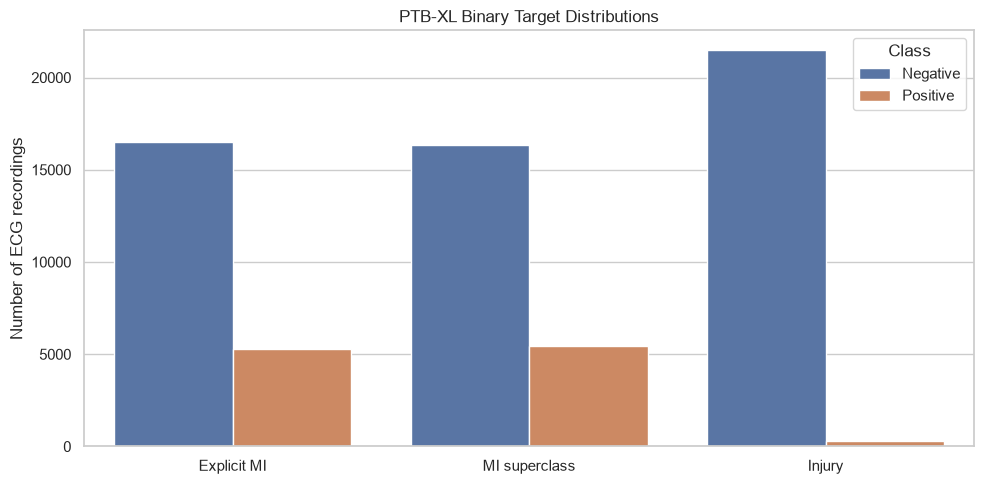

Primary explicit MI prevalence: 24.26%


In [10]:
plot_data = pd.DataFrame({
    "Target": ["Explicit MI", "MI superclass", "Injury"],
    "Negative": [
        int((metadata["mi_label"] == 0).sum()),
        int((metadata["mi_superclass_label"] == 0).sum()),
        int((metadata["injury_label"] == 0).sum()),
    ],
    "Positive": [
        int(metadata["mi_label"].sum()),
        int(metadata["mi_superclass_label"].sum()),
        int(metadata["injury_label"].sum()),
    ],
})

plot_long = plot_data.melt(
    id_vars="Target",
    var_name="Class",
    value_name="Recordings",
)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=plot_long,
    x="Target",
    y="Recordings",
    hue="Class",
)
plt.title("PTB-XL Binary Target Distributions")
plt.xlabel("")
plt.ylabel("Number of ECG recordings")
plt.tight_layout()
plt.show()

print("Primary explicit MI prevalence: {:.2f}%".format(
    100 * metadata["mi_label"].mean()
))

## Step 9: Build anatomical localization mapping

In [ ]:
localization_map = (
    explicit_mi_statements["diagnostic_subclass"]
    .dropna()
    .astype(str)
    .to_dict()
)

print("Explicit MI code -> diagnostic subclass")
for code_name in sorted(localization_map):
    row = explicit_mi_statements.loc[code_name]
    print(
        f"{code_name:8s} -> {localization_map[code_name]:8s} | "
        f"{row['description']}"
    )

if not localization_map:
    raise ValueError(
        "No localization mapping found. Inspect diagnostic_subclass "
        "values in the downloaded SCP statement table."
    )

localization_classes = sorted(set(localization_map.values()))
print("\nLocalization subclasses:", localization_classes)

Explicit MI code -> diagnostic subclass
ALMI     -> AMI      | anterolateral myocardial infarction
AMI      -> AMI      | anterior myocardial infarction
ASMI     -> AMI      | anteroseptal myocardial infarction
ILMI     -> IMI      | inferolateral myocardial infarction
IMI      -> IMI      | inferior myocardial infarction
IPLMI    -> IMI      | inferoposterolateral myocardial infarction
IPMI     -> IMI      | inferoposterior myocardial infarction
LMI      -> LMI      | lateral myocardial infarction
PMI      -> PMI      | posterior myocardial infarction

Localization subclasses: ['AMI', 'IMI', 'LMI', 'PMI']


## Step 10: Extract multilabel localization targets

In [12]:
def extract_localization_labels(
    scp_codes: dict[str, float],
    code_to_subclass: dict[str, str],
) -> list[str]:
    """Extract unique localization subclasses from an ECG's SCP codes."""
    labels = {
        code_to_subclass[code]
        for code in scp_codes
        if code in code_to_subclass
    }
    return sorted(labels)


metadata["mi_localization"] = metadata["scp_codes_parsed"].apply(
    lambda codes: extract_localization_labels(codes, localization_map)
)

localization_columns = [
    f"loc_{subclass}" for subclass in localization_classes
]

for subclass, column in zip(localization_classes, localization_columns):
    metadata[column] = metadata["mi_localization"].apply(
        lambda labels: int(subclass in labels)
    )

# Non-MI recordings must not receive positive localization labels under
# this construction.
if localization_columns:
    non_mi_localization_sum = (
        metadata.loc[metadata["mi_label"].eq(0), localization_columns]
        .to_numpy()
        .sum()
    )
    assert non_mi_localization_sum == 0

display(
    metadata[
        ["mi_label", "mi_localization"] + localization_columns
    ].head(15)
)

,mi_label,mi_localization,loc_AMI,loc_IMI,loc_LMI,loc_PMI
ecg_id,,,,,,
1,0,[],0,0,0,0
2,0,[],0,0,0,0
3,0,[],0,0,0,0
4,0,[],0,0,0,0
5,0,[],0,0,0,0
6,0,[],0,0,0,0
7,0,[],0,0,0,0
8,1,[IMI],0,1,0,0
9,0,[],0,0,0,0


## Step 11: Localization frequency and class imbalance

,recording_count,percentage_of_all_recordings,percentage_of_explicit_MI_recordings
loc_IMI,3238,14.854,61.233
loc_AMI,2830,12.982,53.517
loc_LMI,201,0.922,3.801
loc_PMI,17,0.078,0.321


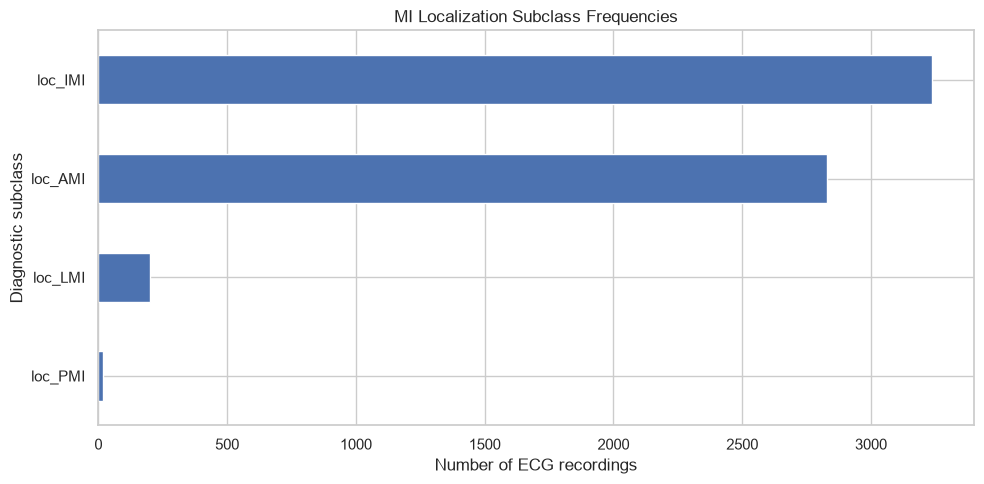

In [13]:
localization_counts = (
    metadata[localization_columns]
    .sum()
    .astype(int)
    .sort_values(ascending=False)
)

localization_summary = pd.DataFrame({
    "recording_count": localization_counts,
    "percentage_of_all_recordings": (
        localization_counts / len(metadata) * 100
    ),
    "percentage_of_explicit_MI_recordings": (
        localization_counts / max(int(metadata["mi_label"].sum()), 1) * 100
    ),
})

display(localization_summary.round(3))

plt.figure(figsize=(10, 5))
localization_counts.sort_values().plot(kind="barh")
plt.title("MI Localization Subclass Frequencies")
plt.xlabel("Number of ECG recordings")
plt.ylabel("Diagnostic subclass")
plt.tight_layout()
plt.show()

## Step 12: Analyze multilabel overlap

Number of localization labels among explicit MI-positive ECGs:


,recording_count
number_of_localization_labels,
1,4291
2,996
3,1


MI-positive ECGs with multiple subclasses: 997
Percentage of MI-positive ECGs with multiple subclasses: 18.85%


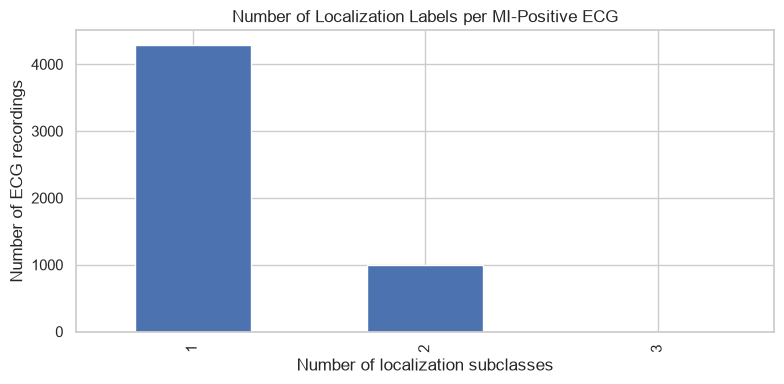

In [14]:
metadata["number_of_localizations"] = (
    metadata[localization_columns].sum(axis=1).astype(int)
)

mi_localization_overlap = (
    metadata.loc[metadata["mi_label"].eq(1), "number_of_localizations"]
    .value_counts()
    .sort_index()
)

print("Number of localization labels among explicit MI-positive ECGs:")
display(
    mi_localization_overlap.rename_axis(
        "number_of_localization_labels"
    ).to_frame("recording_count")
)

multiple_localization_count = int(
    (
        metadata["mi_label"].eq(1)
        & metadata["number_of_localizations"].gt(1)
    ).sum()
)

print("MI-positive ECGs with multiple subclasses:", multiple_localization_count)
print(
    "Percentage of MI-positive ECGs with multiple subclasses: "
    f"{100 * multiple_localization_count / max(int(metadata['mi_label'].sum()), 1):.2f}%"
)

plt.figure(figsize=(8, 4))
mi_localization_overlap.plot(kind="bar")
plt.title("Number of Localization Labels per MI-Positive ECG")
plt.xlabel("Number of localization subclasses")
plt.ylabel("Number of ECG recordings")
plt.tight_layout()
plt.show()

## Step 13: ssign official train, validation, and test splits

In [15]:
fold_numeric = pd.to_numeric(metadata["strat_fold"], errors="coerce")

if fold_numeric.isna().any():
    raise ValueError("Missing or non-numeric strat_fold values detected.")

if not fold_numeric.isin(range(1, 11)).all():
    invalid_folds = sorted(fold_numeric.loc[~fold_numeric.isin(range(1, 11))].unique())
    raise ValueError(f"Unexpected fold values: {invalid_folds}")

metadata["dataset_split"] = np.select(
    [
        fold_numeric.between(1, 8),
        fold_numeric.eq(9),
        fold_numeric.eq(10),
    ],
    ["train", "validation", "test"],
    default="unknown",
)

if metadata["dataset_split"].eq("unknown").any():
    raise ValueError("Some records were not assigned to a known split.")

split_summary = (
    metadata.groupby("dataset_split", sort=False)
    .agg(
        total_recordings=("mi_label", "size"),
        explicit_mi_positive=("mi_label", "sum"),
        mi_prevalence=("mi_label", "mean"),
        broad_mi_positive=("mi_superclass_label", "sum"),
        injury_positive=("injury_label", "sum"),
    )
)

split_summary["mi_prevalence_percent"] = (
    100 * split_summary["mi_prevalence"]
)

display(split_summary.round(4))

,total_recordings,explicit_mi_positive,mi_prevalence,broad_mi_positive,injury_positive,mi_prevalence_percent
dataset_split,,,,,,
train,17418,4235,0.2431,4379,256,24.3139
validation,2183,521,0.2387,540,36,23.8662
test,2198,532,0.2420,550,31,24.2038


## Step 14: Verify patient-level separation

In [16]:
patient_split_counts = (
    metadata.groupby("patient_id")["dataset_split"]
    .nunique()
)

patients_in_multiple_splits = patient_split_counts[
    patient_split_counts > 1
]

print("Patients appearing in multiple splits:", len(patients_in_multiple_splits))

if len(patients_in_multiple_splits) > 0:
    display(patients_in_multiple_splits.head(20))
    raise AssertionError(
        "Patient leakage detected: at least one patient occurs in multiple splits."
    )

print("PASS: no patient appears in more than one split.")

Patients appearing in multiple splits: 0
PASS: no patient appears in more than one split.


## Step 15: Check label prevalence across splits

,explicit_mi_percent,mi_superclass_percent,injury_percent
dataset_split,,,
test,24.204,25.023,1.410
train,24.314,25.141,1.470
validation,23.866,24.737,1.649


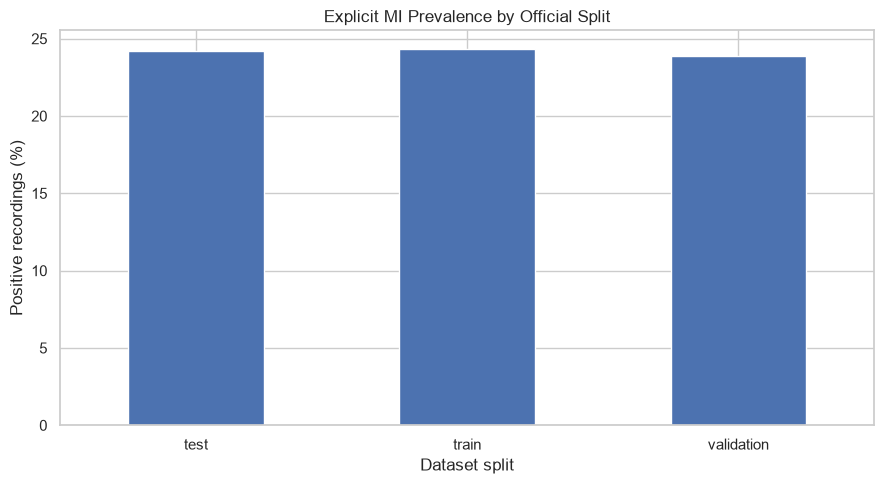

In [17]:
prevalence_by_split = (
    metadata.groupby("dataset_split")[["mi_label", "mi_superclass_label", "injury_label"]]
    .mean()
    .mul(100)
    .rename(columns={
        "mi_label": "explicit_mi_percent",
        "mi_superclass_label": "mi_superclass_percent",
        "injury_label": "injury_percent",
    })
)

display(prevalence_by_split.round(3))

plt.figure(figsize=(9, 5))
(prevalence_by_split["explicit_mi_percent"]).plot(
    kind="bar",
    rot=0,
)
plt.title("Explicit MI Prevalence by Official Split")
plt.xlabel("Dataset split")
plt.ylabel("Positive recordings (%)")
plt.tight_layout()
plt.show()

## Step 16: Export the label metadata

In [18]:
label_columns = [
    "patient_id",
    "strat_fold",
    "dataset_split",
    "mi_label",
    "mi_superclass_label",
    "injury_label",
    "mi_localization",
    "number_of_localizations",
] + localization_columns

label_metadata = metadata[label_columns].copy()

output_path = PROCESSED_DIR / "ptbxl_labels.csv"
label_metadata.to_csv(output_path, index=True)

print("Saved:", output_path.resolve())
print("Output shape:", label_metadata.shape)
display(label_metadata.head(10))

Saved: C:\Users\sintu\Desktop\Myocardial Infarction\data\raw\processed\ptbxl_labels.csv
Output shape: (21799, 12)


,patient_id,strat_fold,dataset_split,mi_label,mi_superclass_label,injury_label,mi_localization,number_of_localizations,loc_AMI,loc_IMI,loc_LMI,loc_PMI
ecg_id,,,,,,,,,,,,
1,15709.0,3,train,0,0,0,[],0,0,0,0,0
2,13243.0,2,train,0,0,0,[],0,0,0,0,0
3,20372.0,5,train,0,0,0,[],0,0,0,0,0
4,17014.0,3,train,0,0,0,[],0,0,0,0,0
5,17448.0,4,train,0,0,0,[],0,0,0,0,0
6,19005.0,4,train,0,0,0,[],0,0,0,0,0
7,16193.0,7,train,0,0,0,[],0,0,0,0,0
8,11275.0,9,validation,1,1,0,[IMI],1,0,1,0,0
9,18792.0,10,test,0,0,0,[],0,0,0,0,0


## Step 17: Save a machine-readable label definition report

In [19]:
import json

label_definition = {
    "primary_detection_target": {
        "column": "mi_label",
        "definition": (
            "1 if at least one diagnostic SCP code has diagnostic_class='MI' "
            "and a description containing 'myocardial infarction'; otherwise 0."
        ),
        "scp_codes": sorted(explicit_mi_codes),
        "likelihood_threshold": None,
        "likelihood_policy": (
            "Code presence; original likelihood values are not thresholded."
        ),
    },
    "secondary_broad_target": {
        "column": "mi_superclass_label",
        "definition": (
            "1 if at least one diagnostic SCP code belongs to diagnostic_class='MI'; "
            "otherwise 0."
        ),
        "scp_codes": sorted(mi_superclass_codes),
    },
    "injury_target": {
        "column": "injury_label",
        "definition": (
            "1 if at least one MI-superclass diagnostic statement description "
            "contains 'injury'; otherwise 0."
        ),
        "scp_codes": sorted(injury_codes),
    },
    "localization": {
        "type": "multilabel",
        "source_column": "diagnostic_subclass",
        "code_to_subclass": localization_map,
        "indicator_columns": localization_columns,
    },
    "split_policy": {
        "train_folds": list(range(1, 9)),
        "validation_folds": [9],
        "test_folds": [10],
        "patient_overlap_verified": len(patients_in_multiple_splits) == 0,
    },
    "dataset": {
        "recordings": int(len(metadata)),
        "unique_patients": int(metadata["patient_id"].nunique()),
    },
}

report_path = PROCESSED_DIR / "label_definition_report.json"

with report_path.open("w", encoding="utf-8") as file:
    json.dump(label_definition, file, indent=4)

print("Saved label definition report:", report_path.resolve())

Saved label definition report: C:\Users\sintu\Desktop\Myocardial Infarction\data\raw\processed\label_definition_report.json


## Step 18: Final validation checklist

In [20]:
for column in ["mi_label", "mi_superclass_label", "injury_label"]:
    assert set(metadata[column].unique()).issubset({0, 1})

assert (metadata["mi_label"] <= metadata["mi_superclass_label"]).all()
assert (metadata["injury_label"] <= metadata["mi_superclass_label"]).all()

for column in localization_columns:
    assert set(metadata[column].unique()).issubset({0, 1})

if localization_columns:
    assert (
        metadata.loc[metadata["mi_label"].eq(0), localization_columns]
        .to_numpy()
        .sum()
        == 0
    )

assert metadata["dataset_split"].isin(
    ["train", "validation", "test"]
).all()
assert len(patients_in_multiple_splits) == 0

assert output_path.exists()
assert report_path.exists()

print("All label-analysis validation checks passed.")
print(f"Label metadata: {output_path}")
print(f"Label definition report: {report_path}")

All label-analysis validation checks passed.
Label metadata: C:\Users\sintu\Desktop\Myocardial Infarction\data\raw\processed\ptbxl_labels.csv
Label definition report: C:\Users\sintu\Desktop\Myocardial Infarction\data\raw\processed\label_definition_report.json
